# Unsupervised Learning Workflow

This notebook uses face images to explore clustering, cluster-derived features, density modeling, sample generation, and anomaly detection.

## Workflow Overview

**Objective:** extract structure from unlabeled data and test whether unsupervised representations help downstream tasks.

**Dataset:** Olivetti faces.

**Primary metrics:** silhouette score for clustering, validation/test accuracy for cluster-derived features, GMM likelihood scores, and PCA reconstruction error for anomaly detection.

**Validation strategy:** train/validation/test splits are stratified by person identity where supervised evaluation is used.

**Production mindset:** unsupervised outputs are inspected visually and quantitatively because cluster labels have no guaranteed real-world meaning without evaluation.

## Stage 0 - Environment Setup

Import clustering, mixture modeling, dimensionality reduction, visualization, and evaluation utilities.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## Stage 1 - Load and Inspect Face Data

Load face vectors and images, create stratified splits, and define a reusable plotting helper.

The Olivetti dataset has:

```text
400 images
40 people
10 images per person
64 x 64 grayscale pixels = 4,096 features
```

The pixels are already scaled between 0 and 1.

In [3]:
faces = fetch_olivetti_faces(shuffle=True, random_state=RANDOM_STATE)
X_faces = faces.data
images = faces.images
y_faces = faces.target

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_faces,
    y_faces,
    test_size=0.2,
    stratify=y_faces,
    random_state=RANDOM_STATE,
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=RANDOM_STATE,
)

X_train.shape, X_valid.shape, X_test.shape

((240, 4096), (80, 4096), (80, 4096))

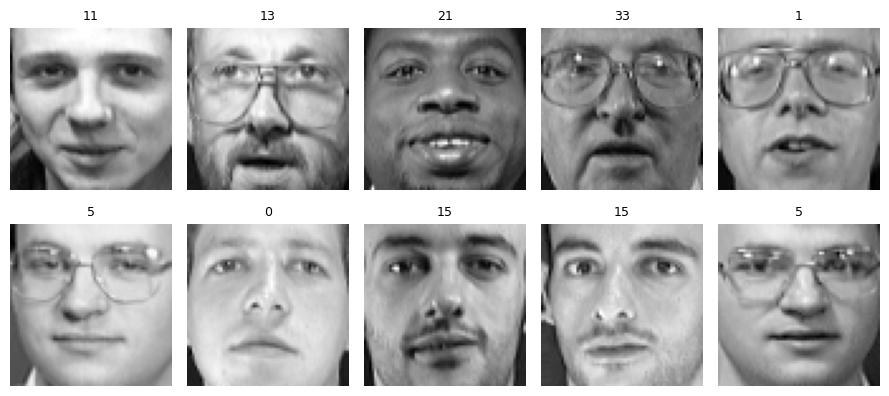

In [5]:
def plot_faces(face_vectors, titles=None, n_cols=5, image_shape=(64, 64), cmap="gray"):
    n_faces = len(face_vectors)
    n_rows = int(np.ceil(n_faces / n_cols))
    plt.figure(figsize=(1.8 * n_cols, 2.1 * n_rows))
    for i, face in enumerate(face_vectors):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(face.reshape(image_shape), cmap=cmap)
        plt.axis("off")
        if titles is not None:
            plt.title(str(titles[i]), fontsize=9)
    plt.tight_layout()
    plt.show()


plot_faces(X_train[10:20], titles=y_train[10:20], n_cols=5)

## Stage 2 - K-Means Clustering and Cluster Inspection

Search over candidate cluster counts, select a useful `k`, and inspect representative faces near cluster centers.

We try several cluster counts and use the silhouette score to choose a reasonable value.

Then we visualize faces closest to selected cluster centers. If clustering works well, some clusters should contain visually similar faces, poses, lighting, or identities.

In [6]:
k_candidates = [20, 30, 40, 50, 60, 80, 100]
cluster_scores = []

for k in k_candidates:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_train)
    score = silhouette_score(X_train, labels)
    cluster_scores.append({"k": k, "silhouette_score": score, "inertia": kmeans.inertia_})

cluster_scores = pd.DataFrame(cluster_scores).sort_values("silhouette_score", ascending=False)
cluster_scores

,k,silhouette_score,inertia
6,100,0.206689,2931.511230
5,80,0.194805,3867.639893
4,60,0.178244,5084.164062
3,50,0.159407,5876.331055
2,40,0.137644,6787.346680
1,30,0.124405,7821.320312
0,20,0.102387,9422.232422


In [7]:
best_k = int(cluster_scores.iloc[0]["k"])
kmeans_faces = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
train_cluster_labels = kmeans_faces.fit_predict(X_train)

best_k, pd.Series(train_cluster_labels).value_counts().describe()

(100,
 count    100.000000
 mean       2.400000
 std        1.091751
 min        1.000000
 25%        2.000000
 50%        2.000000
 75%        3.000000
 max        6.000000
 Name: count, dtype: float64)

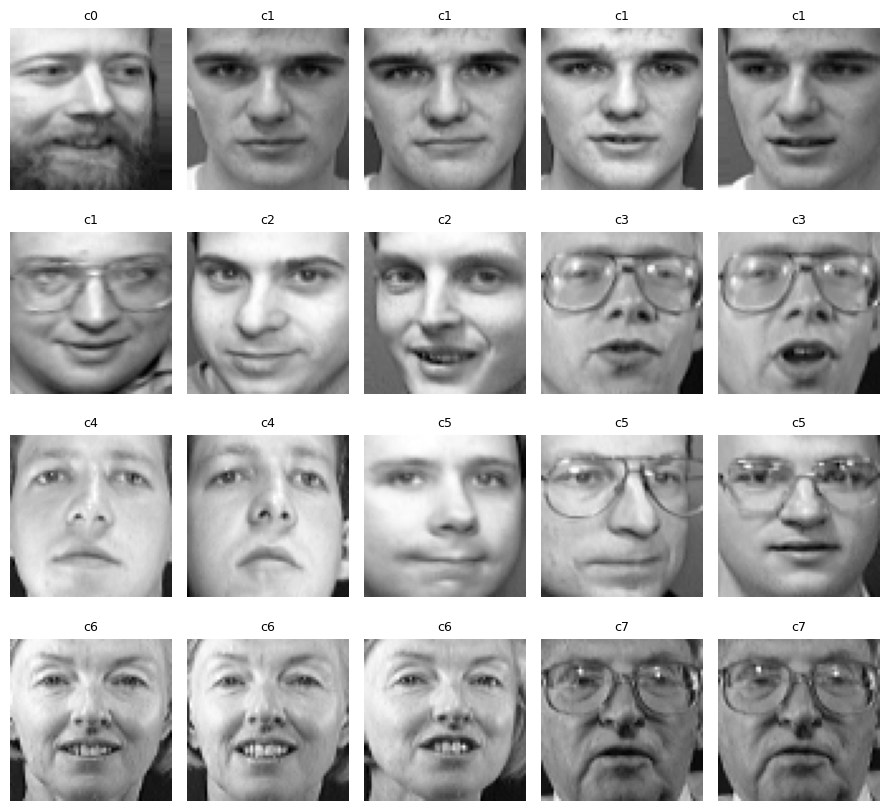

In [10]:
def faces_nearest_cluster_centers(kmeans, X, labels, n_clusters_to_show=8, faces_per_cluster=5):
    selected_faces = []
    selected_titles = []
    for cluster_id in range(min(n_clusters_to_show, kmeans.n_clusters)):
        cluster_indices = np.flatnonzero(labels == cluster_id)
        if len(cluster_indices) == 0:
            continue
        center = kmeans.cluster_centers_[cluster_id]
        distances = np.linalg.norm(X[cluster_indices] - center, axis=1)
        nearest_indices = cluster_indices[np.argsort(distances)[:faces_per_cluster]]
        selected_faces.extend(X[nearest_indices])
        selected_titles.extend([f"c{cluster_id}" for _ in nearest_indices])
    return np.array(selected_faces), selected_titles


cluster_faces, cluster_titles = faces_nearest_cluster_centers(kmeans_faces, X_train, train_cluster_labels)
plot_faces(cluster_faces, titles=cluster_titles, n_cols=5)

## Stage 3 - Cluster-Distance Features for Classification

Use distances to K-Means centroids as learned features and evaluate whether they improve identity classification.

`KMeans.transform(X)` returns distances from each instance to each cluster center.

If there are `k` clusters, each image becomes a `k`-dimensional vector of distances. We can train a classifier on these distance features.

We compare:

1. classifier on original pixels
2. classifier on K-Means distance features only
3. classifier on original pixels plus K-Means distance features

In [8]:
def make_face_classifier():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5_000, random_state=RANDOM_STATE),
    )


baseline_clf = make_face_classifier()
baseline_clf.fit(X_train, y_train)
baseline_valid_accuracy = accuracy_score(y_valid, baseline_clf.predict(X_valid))
baseline_valid_accuracy

0.9875

In [9]:
k_feature_candidates = [20, 30, 40, 60, 80, 100]
feature_search_results = []

for k in k_feature_candidates:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    X_train_dist = kmeans.fit_transform(X_train)
    X_valid_dist = kmeans.transform(X_valid)

    dist_clf = make_face_classifier()
    dist_clf.fit(X_train_dist, y_train)
    dist_accuracy = accuracy_score(y_valid, dist_clf.predict(X_valid_dist))

    X_train_augmented = np.c_[X_train, X_train_dist]
    X_valid_augmented = np.c_[X_valid, X_valid_dist]
    aug_clf = make_face_classifier()
    aug_clf.fit(X_train_augmented, y_train)
    aug_accuracy = accuracy_score(y_valid, aug_clf.predict(X_valid_augmented))

    feature_search_results.append({
        "k": k,
        "kmeans_features_accuracy": dist_accuracy,
        "original_plus_kmeans_accuracy": aug_accuracy,
    })

feature_search_results = pd.DataFrame(feature_search_results)
feature_search_results.sort_values("original_plus_kmeans_accuracy", ascending=False)

,k,kmeans_features_accuracy,original_plus_kmeans_accuracy
0,20,0.7875,0.9875
1,30,0.8750,0.9875
2,40,0.8625,0.9875
3,60,0.9250,0.9875
4,80,0.9000,0.9875
5,100,0.9125,0.9875


In [19]:
best_feature_row = feature_search_results.sort_values("original_plus_kmeans_accuracy", ascending=False).iloc[0]
best_feature_k = int(best_feature_row["k"])

best_feature_kmeans = KMeans(n_clusters=best_feature_k, n_init=10, random_state=RANDOM_STATE)
X_train_full_dist = best_feature_kmeans.fit_transform(X_train_full)
X_test_dist = best_feature_kmeans.transform(X_test)

final_aug_clf = make_face_classifier()
final_aug_clf.fit(np.c_[X_train_full, X_train_full_dist], y_train_full)
final_aug_test_accuracy = accuracy_score(y_test, final_aug_clf.predict(np.c_[X_test, X_test_dist]))

pd.Series({
    "baseline_validation_accuracy": baseline_valid_accuracy,
    "best_k_for_appended_features": best_feature_k,
    "best_validation_accuracy_with_appended_features": best_feature_row["original_plus_kmeans_accuracy"],
    "final_test_accuracy_with_appended_features": final_aug_test_accuracy,
})

baseline_validation_accuracy                        0.9875
best_k_for_appended_features                       20.0000
best_validation_accuracy_with_appended_features     0.9875
final_test_accuracy_with_appended_features          0.9750
dtype: float64

## Stage 4 - Gaussian Mixture Density Modeling

Reduce dimensionality with PCA, fit a Gaussian mixture, generate synthetic face-like samples, and score anomalous transformations.

We reduce dimensionality with PCA first, then fit a Gaussian mixture.

The GMM can:

- generate new face-like samples with `sample()`
- score images with `score_samples()`

Lower scores mean lower density, so the image is more suspicious/anomalous.

In [20]:
pca_99 = PCA(n_components=0.99, random_state=RANDOM_STATE)
X_faces_reduced = pca_99.fit_transform(X_faces)

X_faces_reduced.shape, pca_99.explained_variance_ratio_.sum()

((400, 260), 0.99000543)

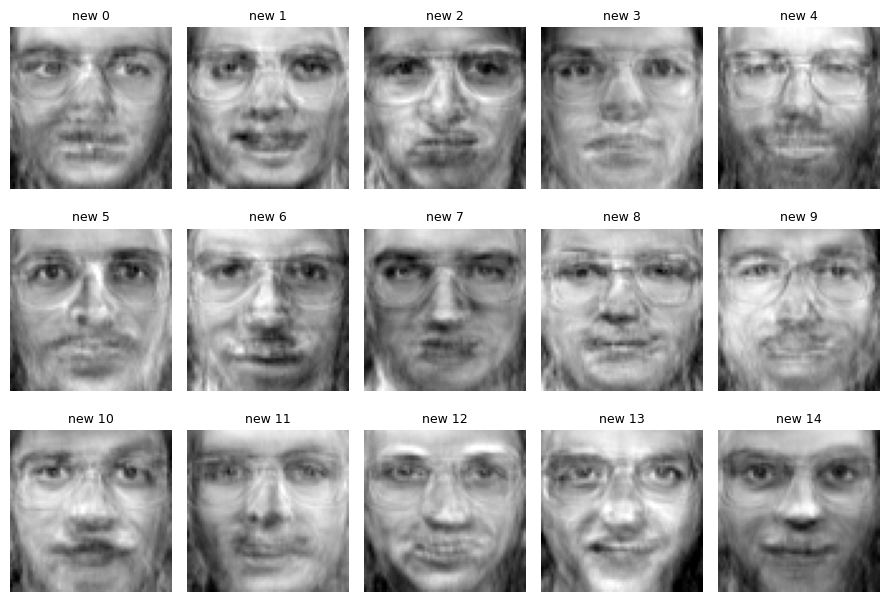

In [13]:
gm = GaussianMixture(
    n_components=40,
    covariance_type="diag",
    max_iter=300,
    n_init=3,
    random_state=RANDOM_STATE,
)
gm.fit(X_faces_reduced)

generated_reduced, generated_labels = gm.sample(15)
generated_faces = np.clip(pca_99.inverse_transform(generated_reduced), 0, 1)

plot_faces(generated_faces, titles=[f"new {i}" for i in range(len(generated_faces))], n_cols=5)

In [14]:
def make_face_anomalies(X, n=10):
    base = X[:n]
    flipped = np.array([np.fliplr(face.reshape(64, 64)).reshape(-1) for face in base])
    darkened = np.clip(base * 0.25, 0, 1)
    rotated = np.array([
        rotate(face.reshape(64, 64), angle=25, reshape=False, mode="constant", cval=0).reshape(-1)
        for face in base
    ])
    return base, flipped, darkened, rotated


normal_faces, flipped_faces, darkened_faces, rotated_faces = make_face_anomalies(X_faces, n=10)

anomaly_score_summary = pd.DataFrame({
    "normal": gm.score_samples(pca_99.transform(normal_faces)),
    "flipped": gm.score_samples(pca_99.transform(flipped_faces)),
    "darkened": gm.score_samples(pca_99.transform(darkened_faces)),
    "rotated": gm.score_samples(pca_99.transform(rotated_faces)),
}).describe().T

anomaly_score_summary

,count,mean,std,min,25%,50%,75%,max
normal,10.0,52.051599,41.879139,8.216276,23.075032,37.385611,69.708327,146.467014
flipped,10.0,-12.815521,50.472138,-84.248375,-55.960897,-10.565271,18.363414,77.054238
darkened,10.0,-42.545328,13.088382,-58.706867,-51.705967,-45.127281,-37.595422,-18.239432
rotated,10.0,-594.327096,129.350246,-753.735563,-668.921212,-636.163101,-522.627309,-346.764322


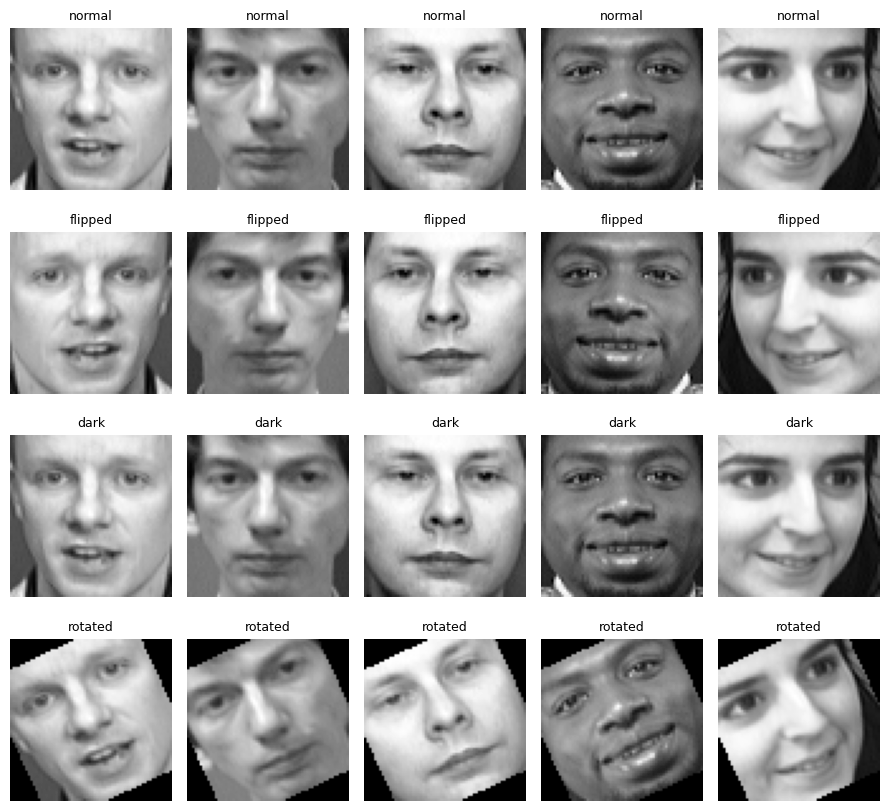

In [21]:
plot_faces(
    np.r_[normal_faces[:5], flipped_faces[:5], darkened_faces[:5], rotated_faces[:5]],
    titles=["normal"] * 5 + ["flipped"] * 5 + ["dark"] * 5 + ["rotated"] * 5,
    n_cols=5,
)

## Stage 5 - Reconstruction-Based Anomaly Detection

Use PCA reconstruction error as a simple anomaly score and visualize normal versus rotated reconstruction quality.

PCA learns how normal faces can be reconstructed from a lower-dimensional representation.

If an image is unusual, PCA reconstructs it poorly, so its reconstruction error tends to be larger.

In [16]:
def reconstruction_errors(pca, X):
    X_reconstructed = pca.inverse_transform(pca.transform(X))
    return np.mean((X - X_reconstructed) ** 2, axis=1)


pca_reconstruction_errors = pd.DataFrame({
    "normal": reconstruction_errors(pca_99, normal_faces),
    "flipped": reconstruction_errors(pca_99, flipped_faces),
    "darkened": reconstruction_errors(pca_99, darkened_faces),
    "rotated": reconstruction_errors(pca_99, rotated_faces),
})

pca_reconstruction_errors.describe().T

,count,mean,std,min,25%,50%,75%,max
normal,10.0,0.000210,0.000058,0.000133,0.000157,0.000212,0.000249,0.000288
flipped,10.0,0.002047,0.000731,0.000825,0.001522,0.002042,0.002503,0.003119
darkened,10.0,0.000594,0.000005,0.000583,0.000591,0.000594,0.000598,0.000601
rotated,10.0,0.012136,0.003043,0.007697,0.009103,0.013664,0.014413,0.015261


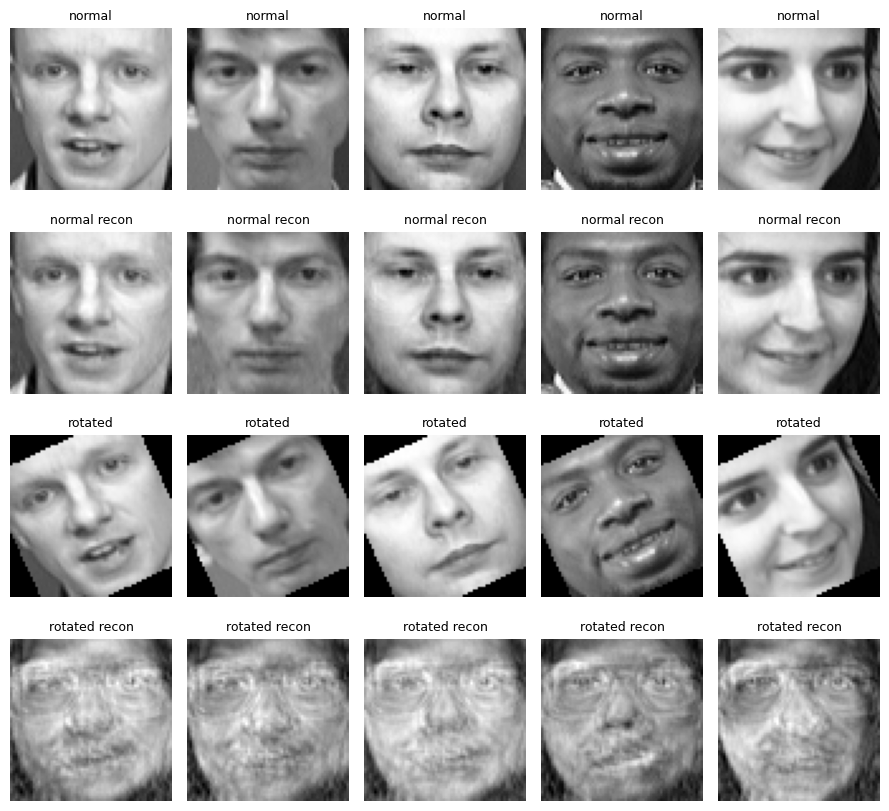

In [22]:
normal_reconstructed = pca_99.inverse_transform(pca_99.transform(normal_faces[:5]))
rotated_reconstructed = pca_99.inverse_transform(pca_99.transform(rotated_faces[:5]))

plot_faces(
    np.r_[normal_faces[:5], normal_reconstructed, rotated_faces[:5], rotated_reconstructed],
    titles=["normal"] * 5 + ["normal recon"] * 5 + ["rotated"] * 5 + ["rotated recon"] * 5,
    n_cols=5,
)

## Workflow Summary and Next Steps

Summarize clustering quality, feature usefulness, density modeling behavior, and practical anomaly-detection caveats.

Notebook complete.

Key ideas:

- clustering groups similar unlabeled instances
- K-Means cluster count can be selected with inertia/elbow or silhouette score
- cluster distances can be used as new features
- Gaussian mixtures can model density, generate samples, and detect low-density anomalies
- PCA reconstruction error can also detect anomalies because unusual inputs reconstruct poorly